## 1. Imports and data loading
Pandas is used for data handling, Matplotlib for charts, and scikit-learn for preprocessing, modelling and evaluation.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay, classification_report

df = pd.read_csv("data/bank-full.csv", sep=";")
print("Dataset dimensions:", df.shape)
display(df.head(10))
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Dataset dimensions: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no



Data types:


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


## 2. Data understanding and preprocessing
Check missing values, duplicates and target balance. The target `y` indicates whether a customer subscribed to a term deposit. Unknown values encoded as `unknown` are treated as a category, and the preprocessing pipeline imputes missing values if any occur.

In [ ]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Target counts:")
display(df["y"].value_counts().to_frame("customers"))
print("Target percentages:")
display((df["y"].value_counts(normalize=True)*100).round(2).to_frame("percent"))


Missing values by column:


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Duplicate rows: 0
Target counts:


,customers
y,
no,39922
yes,5289


Target percentages:


,percent
y,
no,88.3
yes,11.7


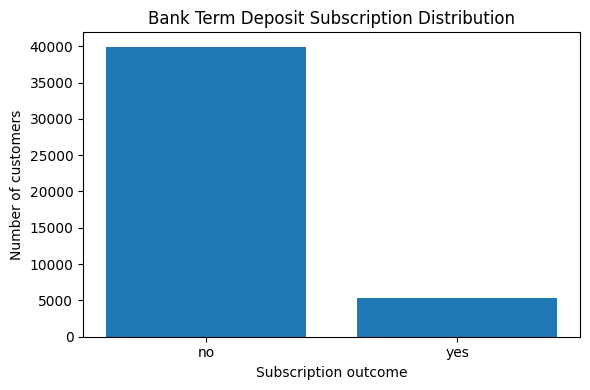

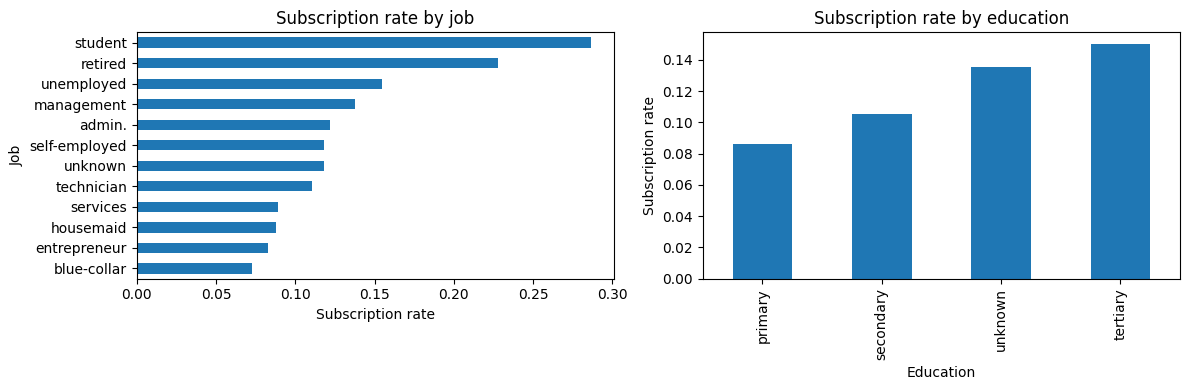

In [ ]:
target_counts = df["y"].value_counts().reindex(["no","yes"])
plt.figure(figsize=(6,4))
plt.bar(target_counts.index, target_counts.values)
plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscription outcome")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
df.groupby("job")["y"].apply(lambda s: (s=="yes").mean()).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Subscription rate by job")
axes[0].set_xlabel("Subscription rate"); axes[0].set_ylabel("Job")
df.groupby("education")["y"].apply(lambda s: (s=="yes").mean()).sort_values().plot(kind="bar", ax=axes[1])
axes[1].set_title("Subscription rate by education")
axes[1].set_xlabel("Education"); axes[1].set_ylabel("Subscription rate")
plt.tight_layout(); plt.show()


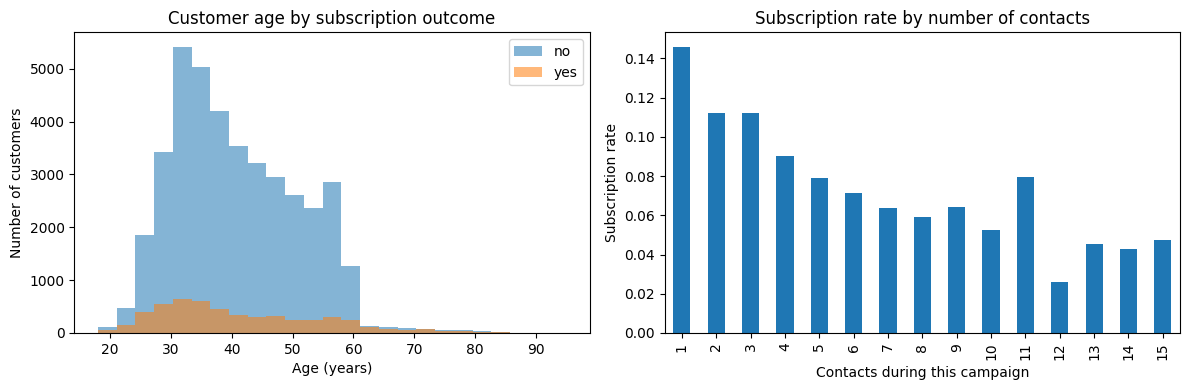

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for label in ["no","yes"]:
    axes[0].hist(df.loc[df["y"]==label, "age"], bins=25, alpha=.55, label=label)
axes[0].set_title("Customer age by subscription outcome")
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Number of customers"); axes[0].legend()
df.groupby("campaign")["y"].apply(lambda s: (s=="yes").mean()).head(15).plot(kind="bar", ax=axes[1])
axes[1].set_title("Subscription rate by number of contacts")
axes[1].set_xlabel("Contacts during this campaign"); axes[1].set_ylabel("Subscription rate")
plt.tight_layout(); plt.show()


### Evidence-based EDA observations
1. The target distribution is imbalanced; a model can achieve a seemingly strong accuracy while still missing many subscribers.
2. Subscription rates vary across job and education categories, suggesting that customer attributes may carry predictive information.
3. The relationship between the number of campaign contacts and subscription should be interpreted carefully; repeated contact may reflect prior campaign difficulty rather than cause subscription.

## 3. Train-test split and feature preprocessing
The `duration` field is deliberately removed to support pre-contact prediction. Categorical fields are one-hot encoded; numeric fields are median-imputed and standardized. A stratified split with `random_state=42` makes the comparison reproducible.

In [ ]:
target = "y"
drop_cols = ["y", "duration"]
X = df.drop(columns=drop_cols)
y = (df[target] == "yes").astype(int)
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Numerical predictors:", numeric_features)
print("Categorical predictors:", categorical_features)


Training rows: 36168 | Test rows: 9043
Numerical predictors: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical predictors: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 4. Train four classification models
All models share the same preprocessing and test split. Accuracy, precision, recall, F1-score and ROC-AUC are reported. Because the target is imbalanced, do not select the model using accuracy alone.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
}
fitted = {}
predictions = {}
probabilities = {}
rows = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:,1]
    fitted[name] = pipe
    predictions[name] = pred
    probabilities[name] = prob
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })
results = pd.DataFrame(rows).set_index("Model").sort_values("F1-score", ascending=False)
display(results.round(4))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.8663,0.4412,0.5359,0.4840,0.8027
Decision Tree,0.8122,0.3319,0.5974,0.4267,0.7764
Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722
KNN,0.8926,0.6516,0.1767,0.2781,0.7369


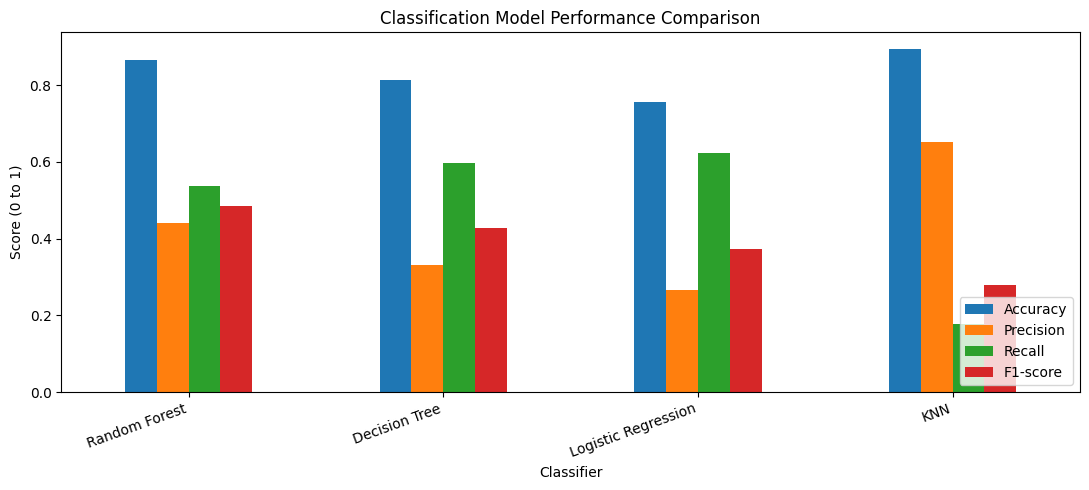

In [ ]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score"]
results[metrics_to_plot].plot(kind="bar", figsize=(11,5))
plt.title("Classification Model Performance Comparison")
plt.xlabel("Classifier"); plt.ylabel("Score (0 to 1)")
plt.xticks(rotation=20, ha="right"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()


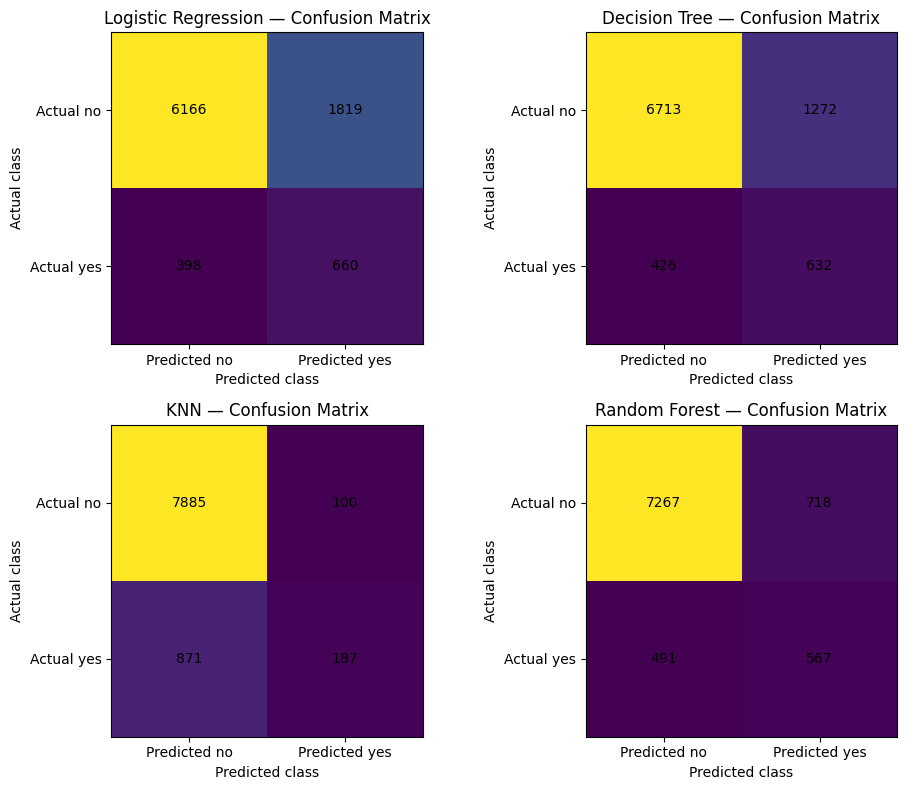

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10,8))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, interpolation="nearest")
    ax.set_title(name + " — Confusion Matrix")
    ax.set_xticks([0,1], ["Predicted no","Predicted yes"])
    ax.set_yticks([0,1], ["Actual no","Actual yes"])
    for i in range(2):
        for j in range(2): ax.text(j, i, str(cm[i,j]), ha="center", va="center")
    ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
plt.tight_layout(); plt.show()


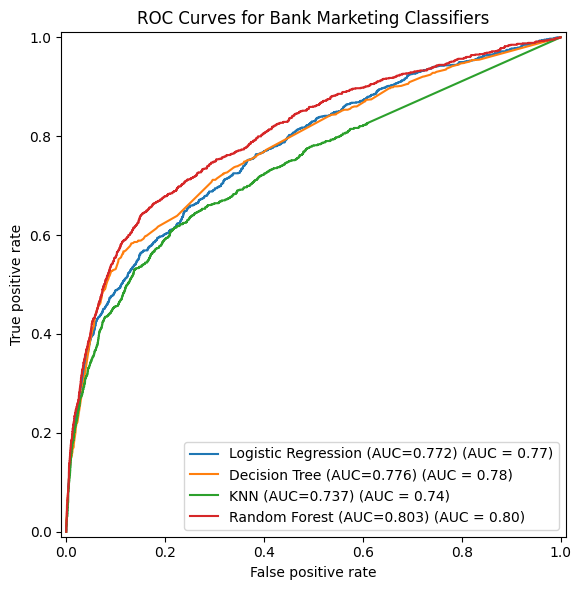

In [ ]:
plt.figure(figsize=(8,6))
for name, prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})", ax=plt.gca())
plt.title("ROC Curves for Bank Marketing Classifiers")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.tight_layout(); plt.show()


## 5. Compare and select a model
Use the generated results table and ROC curves to choose a model. For campaign targeting, recall identifies more likely subscribers, while precision indicates how many selected customers actually subscribe. Higher recall may increase calls to customers who do not subscribe; lower recall may miss potential subscribers.

In [ ]:
best_model_name = results["F1-score"].idxmax()
print("Best model by F1-score:", best_model_name)
print("\nClassification report for selected model:")
print(classification_report(y_test, predictions[best_model_name], target_names=["No subscription","Subscription"], zero_division=0))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions[best_model_name]))


Best model by F1-score: Random Forest

Classification report for selected model:
                 precision    recall  f1-score   support

No subscription       0.94      0.91      0.92      7985
   Subscription       0.44      0.54      0.48      1058

       accuracy                           0.87      9043
      macro avg       0.69      0.72      0.70      9043
   weighted avg       0.88      0.87      0.87      9043


Confusion matrix:
[[7267  718]
 [ 491  567]]


## 6. Business recommendations, limitations and conclusion

**Business recommendations**
1. Use the selected model to rank customers by predicted subscription probability and prioritize outreach, validating the strategy with a controlled campaign experiment.
2. Select the decision threshold based on the bank's contact costs and the relative value of finding a subscriber; do not assume 0.50 is always optimal.

**Limitations**
1. The dataset is historical and may not reflect current customer behaviour or market conditions.
2. Some categorical values are recorded as `unknown`; this may reduce information quality.
3. The model predicts association rather than causal impact, and campaign decisions based on it should be monitored for drift and unintended bias.

**Conclusion:** The final model should be justified using the actual test-set metrics, confusion matrix and ROC-AUC values printed above. Accuracy alone is insufficient because subscribers are the minority class.